In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
adv = pd.read_csv('/kaggle/input/datasets/amrbakr95/advertising-sales/advertising.csv')
adv.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
adv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [4]:
adv.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [5]:
adv.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [6]:
adv.duplicated().sum()

np.int64(0)

In [7]:
adv.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

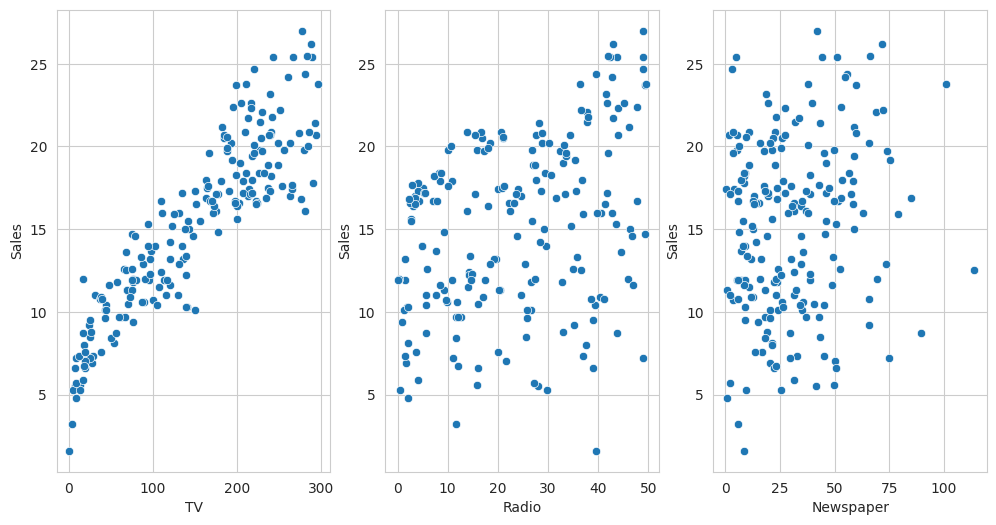

In [8]:
typeOfAdv=['TV', 'Radio', 'Newspaper']
plt.figure(figsize=(12,6))
for i , col in enumerate (typeOfAdv,start=1):
    plt.subplot(1,3,i)
    sns.scatterplot(x=col,y='Sales',data=adv)
    plt.xlabel(col)
    plt.ylabel('Sales')
plt.show()

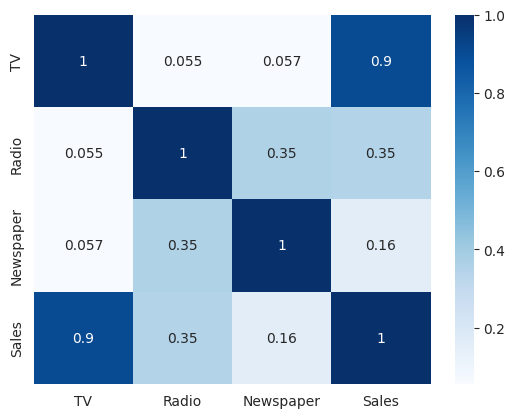

In [9]:
corr= adv.corr()
sns.heatmap(corr,annot=True,cmap='Blues')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X= adv[['TV']]
y= adv['Sales']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)

(160, 1)
(40, 1)


In [12]:
from sklearn.linear_model import LinearRegression
model =LinearRegression()
model.fit(X_train,y_train)
print(f'b:{model.intercept_}')
print(f'w:{model.coef_}')


b:7.007108428241848
w:[0.05548294]


In [13]:
randomNumbers=np.linspace(0,400,80)
line=model.coef_*randomNumbers+model.intercept_

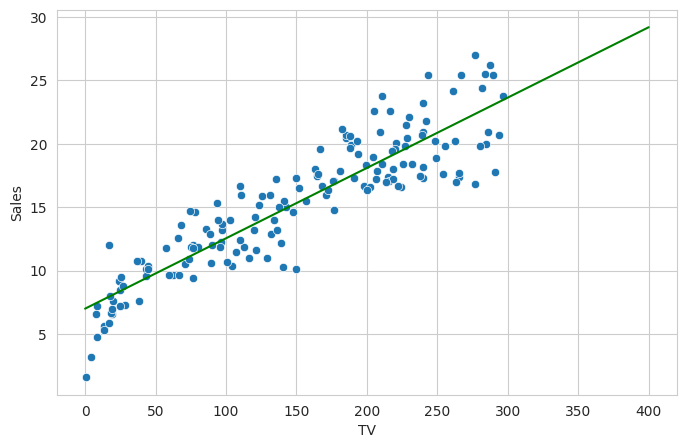

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x= X_train['TV'],y= y_train)
sns.lineplot(x=randomNumbers,y=line,color='green')
plt.show()

In [15]:
import pandas as pd

new_data = pd.DataFrame({"TV": [100]})
model.predict(new_data)

array([12.55540282])

In [16]:
y_pred=model.predict(X_test)
y_pred

array([16.06747317, 17.84847567, 23.25806271,  7.65625887, 19.23000098,
       11.17387752, 19.03581067,  9.78125562, 19.34651516, 16.72217191,
        8.75482116, 10.12524988, 20.01785878,  7.30671633, 14.74697911,
       16.45030549,  7.41213392, 17.97053815, 11.18497411, 20.17875932,
       19.74044406, 10.76885203,  9.1154603 , 20.92777906, 10.83543156,
        9.97544593, 18.85271696, 14.73588252, 11.84522114,  7.47316516,
       18.09260063, 10.84652815, 18.04266598,  7.94477018, 22.58117079,
       20.22314567,  9.68693462, 22.19279018, 13.50970946,  8.53288939])

In [17]:
Error=y_test-y_pred
Error=pd.DataFrame({'y_test':y_test,'y_pred':y_pred,'Error':(y_test-y_pred)})
Error.head()

,y_test,y_pred,Error
95,16.9,16.067473,0.832527
15,22.4,17.848476,4.551524
30,21.4,23.258063,-1.858063
158,7.3,7.656259,-0.356259
128,24.7,19.230001,5.469999


In [18]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
MSE=mean_squared_error(y_test,y_pred)
RMSE=np.sqrt(MSE)
MAE = mean_absolute_error(y_test,y_pred)
print(RMSE,MAE)
r2_simple=r2_score(y_test,y_pred)
r2_simple

2.470035001123256 1.9502948931650088


0.802561303423698

In [19]:
from sklearn.model_selection import train_test_split
X= adv[['TV', 'Radio', 'Newspaper']]
y=adv['Sales']
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [20]:
from sklearn.linear_model import LinearRegression
model =LinearRegression()
model.fit(X_train,y_train)
print(f'Sita0 (b) : {model.intercept_}')
print(f'Sita1: (w of Tv) : {model.coef_[0].round(2)},Sita2: (w of Radio) : {model.coef_[1]}, Sita3: (w of Newspaper) : {model.coef_[2]}')

Sita0 (b) : 4.714126402214127
Sita1: (w of Tv) : 0.05,Sita2: (w of Radio) : 0.10094536239295579, Sita3: (w of Newspaper) : 0.0043366468220340446


In [21]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
y_predict=model.predict(X_test)
MSE=mean_squared_error(y_test,y_predict)
print(MSE)
RMSE=np.sqrt(MSE)
print(RMSE)
r2_Multi=r2_score(y_test,y_predict)
print(r2_Multi)


2.9077569102710896
1.7052146229349223
0.9059011844150826


<Axes: >

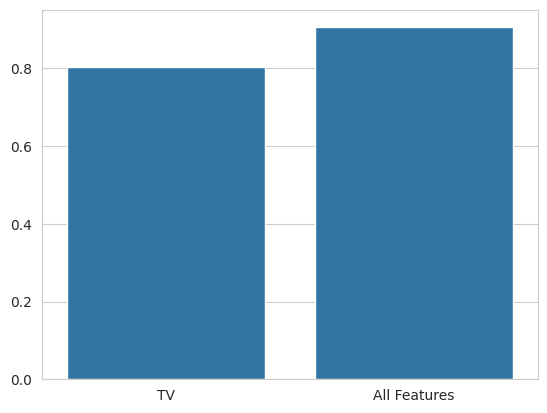

In [22]:
sns.barplot(x=['TV','All Features'], y=[r2_simple, r2_Multi])